In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt

In [16]:
wax = pd.read_excel('PlantWax_isotope_amazon.xls',
                    sheet_name='All_data', skiprows=[1], engine='xlrd')
wax = wax.dropna(subset=['Site']).copy()
wax.columns = wax.columns.str.strip()
print('Labeled samples:', len(wax))
wax.head()
isotope_cols = ['alkane_C27', 'alkane_C29', 'alkane_C31', 'alkane_C33',
                'acid_C24', 'acid_C26', 'acid_C28', 'acid_C30']

data = wax[['Site', 'Vegetation Type', 'Lat', 'Long']].copy()
# Columns 29 to 36 are the Suess-effect-corrected soil measurements.
data[isotope_cols] = wax.iloc[:, 29:37].apply(pd.to_numeric, errors='coerce').to_numpy()
# Retain incomplete specimens until AFTER averaging the available values.
data['Vegetation Type'] = data['Vegetation Type'].str.replace(r'\s+', ' ', regex=True).str.strip()
data.head()


Labeled samples: 236


,Site,Vegetation Type,Lat,Long,alkane_C27,alkane_C29,alkane_C31,alkane_C33,acid_C24,acid_C26,acid_C28,acid_C30
0,GRU1a,Atlantic rainforest,-23.327,-46.425,-34.494843,-34.323923,-34.908023,-34.290729,-32.564959,-32.366252,-32.372000,-33.339515
1,GRU1b,Atlantic rainforest,-23.327,-46.425,-33.184952,-33.767566,-35.086870,-34.550825,-33.221504,-33.162788,-32.975556,-34.602703
2,GRU1c,Atlantic rainforest,-23.327,-46.425,-33.053170,-32.761367,-33.694244,-33.517874,-32.734172,-33.031475,-32.527556,-35.431966
3,GRU2a,Atlantic rainforest,-23.222,-46.429,-31.050186,-34.058377,-34.294693,-32.590447,-32.344982,-31.884771,-32.169778,-33.457502
4,GRU2b,Atlantic rainforest,-23.222,-46.429,-32.706376,-33.897366,-35.139880,-35.008098,-32.954712,-32.954034,-32.730296,-34.809040


In [3]:
isotope_cols = ['alkane_C27', 'alkane_C29', 'alkane_C31', 'alkane_C33',
                'acid_C24', 'acid_C26', 'acid_C28', 'acid_C30']

data = wax[['Site', 'Vegetation Type', 'Lat', 'Long']].copy()

# Columns 29 to 36 contain the eight Suess-effect-corrected soil measurements.
data[isotope_cols] = wax.iloc[:, 29:37].apply(pd.to_numeric, errors='coerce').to_numpy()
data = data.dropna(subset=isotope_cols).reset_index(drop=True)
print('Complete samples:', len(data))
data.head()


Complete samples: 224


,Site,Vegetation Type,Lat,Long,alkane_C27,alkane_C29,alkane_C31,alkane_C33,acid_C24,acid_C26,acid_C28,acid_C30
0,GRU1a,Atlantic rainforest,-23.327,-46.425,-34.494843,-34.323923,-34.908023,-34.290729,-32.564959,-32.366252,-32.372000,-33.339515
1,GRU1b,Atlantic rainforest,-23.327,-46.425,-33.184952,-33.767566,-35.086870,-34.550825,-33.221504,-33.162788,-32.975556,-34.602703
2,GRU1c,Atlantic rainforest,-23.327,-46.425,-33.053170,-32.761367,-33.694244,-33.517874,-32.734172,-33.031475,-32.527556,-35.431966
3,GRU2a,Atlantic rainforest,-23.222,-46.429,-31.050186,-34.058377,-34.294693,-32.590447,-32.344982,-31.884771,-32.169778,-33.457502
4,GRU2b,Atlantic rainforest,-23.222,-46.429,-32.706376,-33.897366,-35.139880,-35.008098,-32.954712,-32.954034,-32.730296,-34.809040


### Set the vegetation classes and sampling groups

In [4]:
vegetation = data['Vegetation Type']
data['Vegetation'] = 'Savanna'
forest = vegetation.str.contains(
    'rainforest|riparian forest|mauritia swamp|dry forest|plotted with Cerradao')
data.loc[forest, 'Vegetation'] = 'Forest'
data.loc[vegetation == 'Caatinga', 'Vegetation'] = 'Shrubland'
print('Source specimen classes:')
print(data['Vegetation'].value_counts())


Source specimen classes:
Vegetation
Forest       106
Savanna       98
Shrubland     20
Name: count, dtype: int64


In [5]:
sites = data['Site'].str.upper()
data['Plot'] = sites.str.extract(r'^((?:GRU|SX|SFS)\d+)', expand=False).fillna(sites)

# Average matching plot subsamples; full Llanos IDs remain separate.
keys = ['Plot', 'Vegetation Type', 'Vegetation', 'Lat', 'Long']
replicates = data.groupby(keys, sort=False)
replicate_counts = replicates[isotope_cols].count()
replicate_sd = replicates[isotope_cols].std()  # NaN is normal for a single sample.
data = replicates[isotope_cols].mean().join(
    replicates.size().rename('n_samples')).reset_index()
print('Observations before completeness filtering:', len(data))
data = data.dropna(subset=isotope_cols).reset_index(drop=True)

# Hold out the nearby Llanos observations together.
data['Group'] = data['Plot']
data.loc[data['Vegetation Type'].str.startswith('Llanos'), 'Group'] = 'Llanos_region'
print('Model observations:', len(data))
print('Validation groups:', data['Group'].nunique())
print(data['Vegetation'].value_counts())


Observations before completeness filtering: 87
Model observations: 87
Validation groups: 46
Vegetation
Forest       51
Savanna      30
Shrubland     6
Name: count, dtype: int64


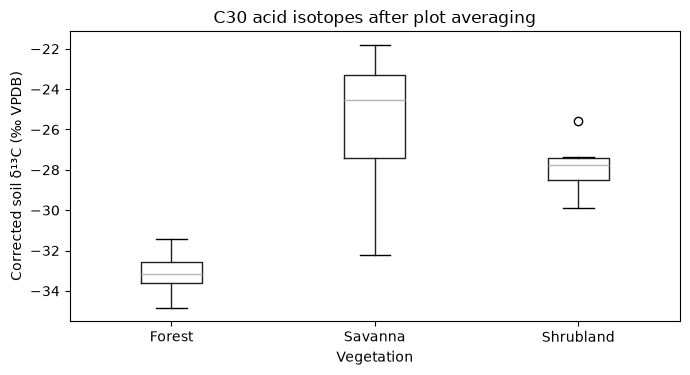

In [15]:
data.boxplot(column='acid_C30', by='Vegetation', grid=False, figsize=(7, 4))
plt.title('C30 acid isotopes after plot averaging')
plt.suptitle('')
plt.xlabel('Vegetation')
plt.ylabel('Corrected soil δ¹³C (‰ VPDB)')
plt.tight_layout()
plt.savefig('A.png', dpi=300, bbox_inches='tight')
plt.show()

I will use a few models to see prediction of vegetation types by isotopic value- 
- Logistic Regression
- Random Forest
- Gradient Boosting
- Majority-Class Baseline
- XGBoost (possibly)

In [7]:
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
from sklearn.metrics import ConfusionMatrixDisplay